In [41]:
import os
import h5py

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import corner

%matplotlib inline
plt.style.use('~/default.mplstyle')

In [42]:
label_keys = (
    'df_beta0', 'stellar_log_ra_kpc',
    'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm_kpc', 'dm_log_rho0',
    'stellar_log_rstar_kpc'
)
catalog_path = '/scratch/tvnguyen/projects/sbi_dsph/datasets/8p_ZhaoPlumCOM_v4'

labels = dict()
with h5py.File(os.path.join(catalog_path, 'data.0.h5'), 'r') as f:
    for key in label_keys:
        labels[key] = f[key][()]
    pos = f['pos'][()]
    vel = f['vel'][()]
    ptr = f['ptr'][()]

In [43]:
data = np.stack([labels[key] for key in label_keys]).T

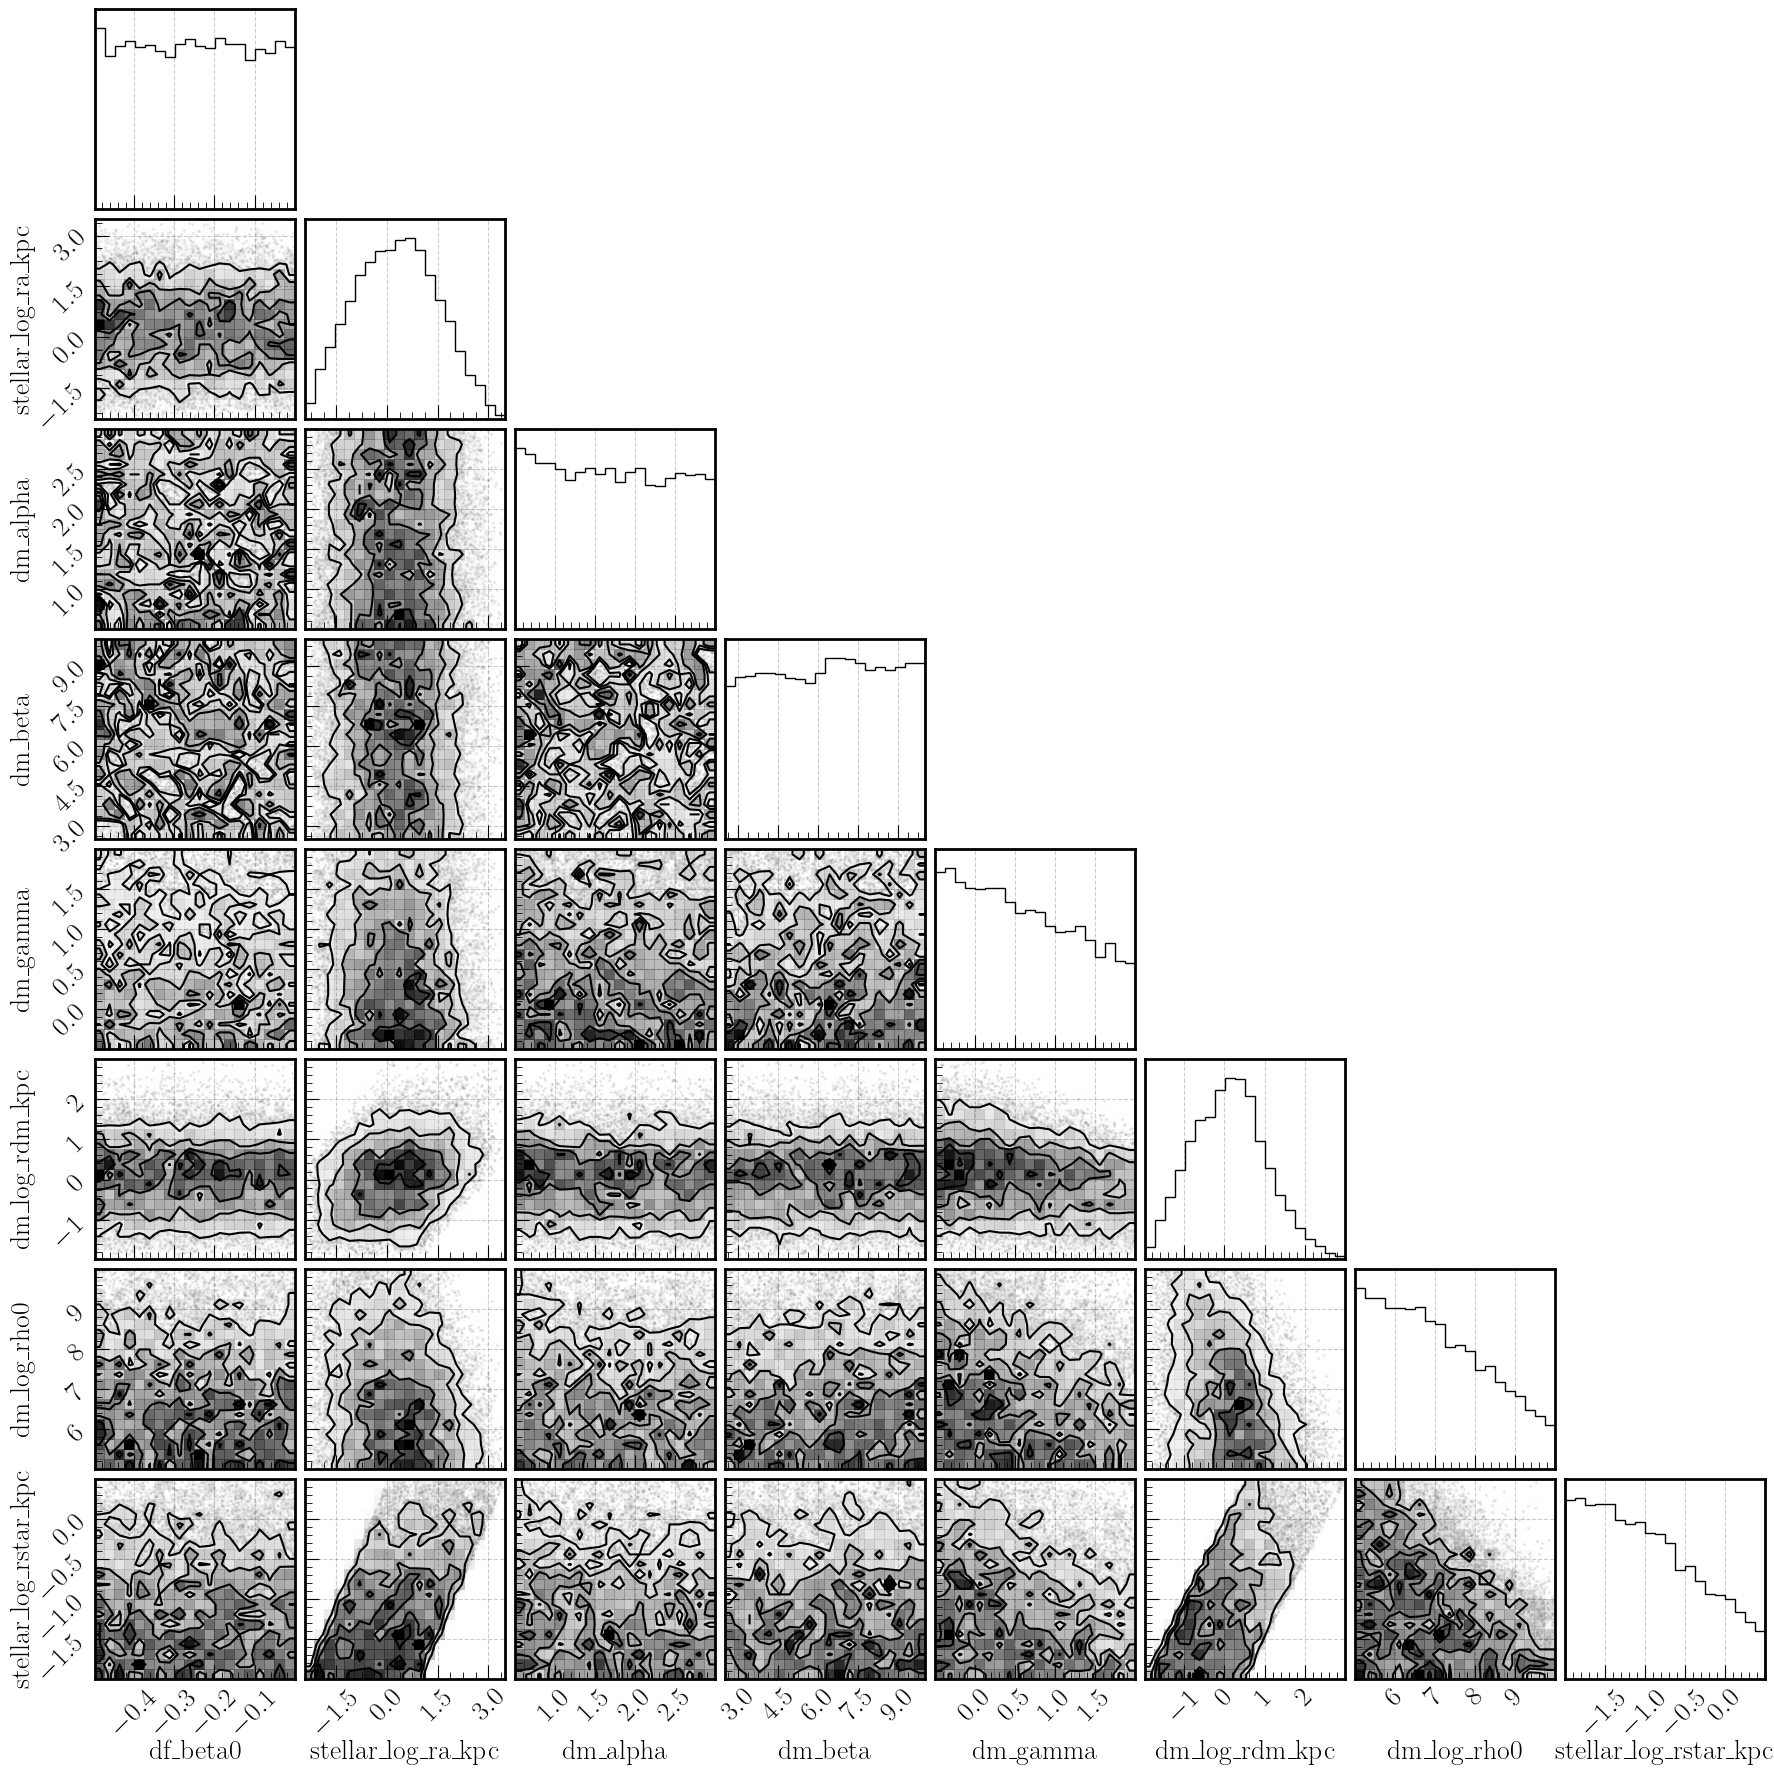

In [44]:
fig = corner.corner(
    data[:10000], labels=label_keys
)

## Dispersion prior

In [45]:
veldisp_3d = []
veldisp_los = []
velmean = []
for i in range(len(ptr) - 1):
    i0, i1 = ptr[i], ptr[i + 1]
    sub_pos = pos[i0:i1]
    sub_vel = vel[i0:i1]
    veldisp_3d.append(np.sqrt(np.sum(np.var(sub_vel, axis=0))))
    veldisp_los.append(np.std(sub_vel[:, 2]))
    velmean.append(np.mean(sub_vel, axis=0))
veldisp_3d = np.array(veldisp_3d)
veldisp_los = np.array(veldisp_los)
velmean = np.array(velmean)

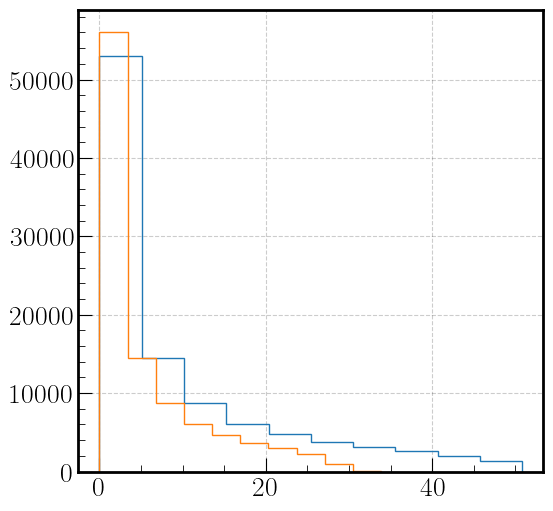

In [46]:
fig, ax = plt.subplots()

ax.hist(veldisp_3d, histtype='step')
ax.hist(veldisp_los, histtype='step')
plt.show()

In [47]:
from dsph_analysis import kinematic_io

In [48]:
# LVDB
meta = kinematic_io.load_meta_table()
# remove LMC and SMC
meta = meta[~meta['key'].isin(['lmc', 'smc'])]

vlos_sigma, vlos_sigma_em, vlos_sigma_ep = meta['vlos_sigma'], meta['vlos_sigma_em'], meta['vlos_sigma_ep']

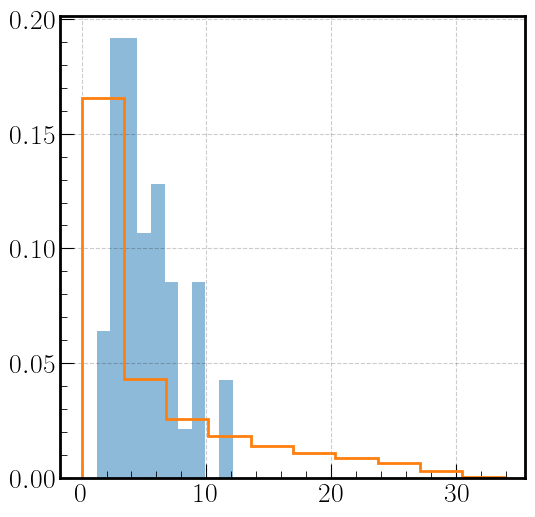

In [50]:
fig, ax = plt.subplots()

ax.hist(vlos_sigma, density=True, alpha=0.5)
ax.hist(veldisp_los, histtype='step', lw=2, density=True)
plt.show()